> 🤖 **Completed afterwards with Claude (2026)**: this assignment was left blank at the time and was finished in 2026. The original blank template is kept at the top.

> Machine Learning · University of Toronto School of Continuing Studies · Winter 2022 · Week 8

### Your name:

<pre> Your name here</pre>

### Collaborators:

<pre> Enter the name of the people you worked with if any</pre>


In [ ]:
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(123)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

### Dimesionality Reduction

Q1. What is the curse of dimensionality? (1 marks)

`Your answer here`

Q2. Can PCA be used to reduce the dimensionality of a highly nonlinear dataset?  (1 marks)

`Your answer here`

Q3. How can you evaluate the performance of a dimensionality reduction algorithm on your dataset? (1 marks)

`Your answer here`

Q4. Load the MNIST dataset (introduced in Module 3) and split it into a training set and a test set. Train a Random Forest classifier on the dataset and time how long it takes by adding `%%time` at the top of the cell. Then evaluate the resulting model on the test set. Use PCA to reduce the dataset’s dimensionality, with an explained variance ratio of 95%. Train a new Random Forest classifier on the reduced dataset and time how long it takes. Was training much faster? Next evaluate the new classifier on the test set. How does it compare to the previous classifier?  (3 marks)

In [ ]:
# Your code here

Q5. Use t-SNE to reduce the MNIST dataset down to two dimensions and plot the result using Matplotlib. You can use a scatterplot using 10 different colors to represent each image’s target class. Alternatively, you can write colored digits at the location of each instance, or even plot scaled-down versions of the digit images themselves. Note: if you plot all digits, the visualization will be too cluttered, so you should either draw a random sample or plot an instance only if no other instance has already been plotted at a close distance. You should get a nice visualization with well-separated clusters of digits. Try using other dimensionality reduction algorithms such as PCA, LLE, or MDS and compare the resulting visualizations. (4 marks)

In [ ]:
# Your code here

[Optional] Read
https://marckhoury.github.io/counterintuitive-properties-of-high-dimensional-space/ and summarize your most interesting finding.

`Your answer here`

---
## 🤖 Completed afterwards with Claude (2026)
Everything above this line is Ketan's original coursework. The cells below were added in 2026 with Claude to finish questions that were left open, and are kept separate so it's clear who did what.

**Q1. What is the curse of dimensionality?**

As the number of features grows, the volume of the space grows exponentially, so any fixed amount of data becomes sparse. Points end up far apart and roughly equidistant, which breaks distance-based methods (kNN, clustering), makes overfitting easier and means you need exponentially more data to cover the space at the same density.

**Q2. Can PCA be used to reduce the dimensionality of a highly nonlinear dataset?**

It can always *reduce* dimensions, but plain PCA is linear: it projects onto flat directions of maximum variance, so it can crush structure that lives on a curved manifold (a Swiss roll is the classic example). For nonlinear data, Kernel PCA, LLE, Isomap, UMAP or t-SNE usually preserve the structure better. PCA still helps if the data has many useless dimensions it can drop.

**Q3. How can you evaluate a dimensionality reduction algorithm?**

1. Reconstruction error (reduce, inverse-transform, compare to the original).
2. Explained variance kept (for PCA).
3. Downstream performance: train the real model on the reduced data and compare accuracy and training time.
4. For visualisation methods, how well classes or neighbourhoods stay separated in the plot.

**Q4. Random Forest on MNIST, with and without PCA (95% variance).**

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='auto')
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

t = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
t_full = time.time() - t
acc_full = accuracy_score(y_test, rf.predict(X_test))

pca = PCA(n_components=0.95, random_state=42)
X_train_r = pca.fit_transform(X_train)
X_test_r = pca.transform(X_test)
t = time.time()
rf_r = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train_r, y_train)
t_red = time.time() - t
acc_red = accuracy_score(y_test, rf_r.predict(X_test_r))

print(f'Components kept for 95% variance: {pca.n_components_} of 784')
print(f'Full data:    {t_full:5.1f} s training, accuracy {acc_full:.4f}')
print(f'PCA-reduced:  {t_red:5.1f} s training, accuracy {acc_red:.4f}')

Components kept for 95% variance: 154 of 784
Full data:     15.6 s training, accuracy 0.9705
PCA-reduced:   18.4 s training, accuracy 0.9488


PCA shrinks 784 pixels to about 150 components, but the Random Forest is **not** faster and gets **less** accurate. Forests split on one feature at a time, and PCA mixes every pixel into dense, rotated components, so each split carries less clean signal and the trees grow deeper. Dimensionality reduction does not always speed things up: it depends on the model (it helps a lot more for kNN, SVMs or logistic regression).

**Q5. t-SNE of MNIST in 2D** (random sample of 5,000 digits so the plot stays readable).

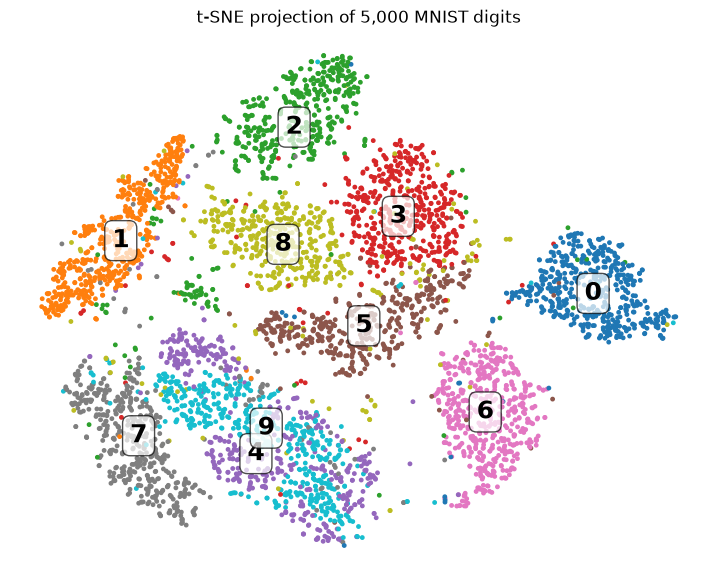

In [2]:
from sklearn.manifold import TSNE
rng = np.random.default_rng(42)
idx = rng.choice(len(X_train), 5000, replace=False)
X2 = TSNE(n_components=2, init='pca', learning_rate='auto', random_state=42).fit_transform(X_train[idx])
labels = y_train[idx].astype(int)
plt.figure(figsize=(9, 7))
sc = plt.scatter(X2[:, 0], X2[:, 1], c=labels, cmap='tab10', s=6)
for d in range(10):
    cx, cy = np.median(X2[labels == d], axis=0)
    plt.text(cx, cy, str(d), fontsize=18, weight='bold', ha='center', va='center',
             bbox=dict(boxstyle='round', fc='white', alpha=0.7))
plt.title('t-SNE projection of 5,000 MNIST digits'); plt.axis('off'); plt.show()

The digits form clear islands. The overlaps make sense visually: 4/9 and 3/5/8 share strokes, while 0, 1, 6 and 2 sit well apart.

**[Optional] Most interesting finding from *Counterintuitive properties of high-dimensional space*:** in high dimensions almost all of a sphere's volume sits in a thin shell near its surface, and random vectors are nearly orthogonal. So "typical" points are all far from the centre and from each other, which is exactly why distances stop being informative (the curse from Q1).